In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
import fspiderman as sp
import batman
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from kepler_utils import *
import batman_utils

looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.0204                                 #planet radius [stellar radii / rs]
rs = 0.68                                   #stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]   
a = AU_to_RS(a_AU, rs)                      #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142e-6                                 #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
T_eff = 4570                                # stellar effective temperature [K]

u = [0.1, 0.3]                              # Stellar limb darkening coefficients [u1, u2] (placeholders, not from K2-141 data, will be set by theoretical stellar atmosphere models)

Ag = 0.28                                   # Geometric albedo from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
A_B = 3/2*Ag                                # Assuming Lambertian reflectance. PROBABLY UNPHYSICAL!

In [3]:
# Define Exoplanet Object
K2_141b = PlanetParams(period=period, incl=incl, ecc=ecc, w=w, r1=rp, r2=1., R=a, T2_eff=T_eff, a_AU=a_AU)

In [4]:
# Wavelength ranges of various instruments in um. These are only effective ranges, used for approximate tophat filters.
effective_lambda_ranges = {
    "MIRI/F1280W": [11.6, 14.0], # MIRI imaging TSO, F1280W. Below CO₂ band, can check CO₂ atmosphere (combined with F1500W)
    "MIRI/F1500W": [13.5, 16.6], # MIRI imaging TSO, F1500W. Used on Trappist (15µm CO₂ band), Long wavelengths for cold nightside
    "MIRI/F1800W": [16.5, 19.5], # MIRI imaging TSO, F1800W. MIRI's thermal background climbs steeply past ~15 µm
    "MIRI/LRS": [5.0, 10.5], # Suggested by Sebastian, LRS runs to ~12 µm but red end trimmed (throughput drops)
    "Spitzer/IRAC2": [4.0, 5.0] # ~Spitzer IRAC channel 2 (4.5 um), to compare with the measured occultation depth fp = 142 ppm (Zieba 2022)
}
for n, r in effective_lambda_ranges.items(): effective_lambda_ranges[n]=1e-6*np.array(r) # convert to meters

# Wavelength ranges of various instruments in um. These are the exact filter ranges to be used with the filter throughput data.
filter_lambda_ranges = {
    "MIRI/F1280W": [11.0654, 14.5816], # MIRI imaging TSO, F1280W. Below CO₂ band, can check CO₂ atmosphere (combined with F1500W)
    "MIRI/F1500W": [12.7875, 17.4925], # MIRI imaging TSO, F1500W. Used on Trappist (15µm CO₂ band), good for cold nightside
    "MIRI/F1800W": [15.5725, 20.8505], # MIRI imaging TSO, F1800W. MIRI's thermal background climbs steeply past ~15 µm
    "Spitzer/IRAC2": [3.6955, 5.1008], # ~Spitzer IRAC channel 2 (4.5 um), to compare with the measured occultation depth fp = 142 ppm (Zieba 2022)
    "MIRI/LRS": [4.8900, 10.6100] # MIRI/LRS 5.0-10.5 um. Filter_paths for 5.0-12.0 um and 5.0-14.0 um are also available.
}
for n, r in filter_lambda_ranges.items(): filter_lambda_ranges[n]=1e-6*np.array(r) # convert to meters

FILTER_DIR = os.path.join(os.path.dirname(os.path.abspath('')), 'Filters', 'Spiderman')
filter_paths = {
    "MIRI/F1280W": os.path.join(FILTER_DIR, "JWST_MIRI.F1280W.spiderman.dat"),
    "MIRI/F1500W": os.path.join(FILTER_DIR, "JWST_MIRI.F1500W.spiderman.dat"),
    "MIRI/F1800W": os.path.join(FILTER_DIR, "JWST_MIRI.F1800W.spiderman.dat"),
    "Spitzer/IRAC2": os.path.join(FILTER_DIR, "Spitzer_IRAC.I2.spiderman.dat"),
    "MIRI/LRS": os.path.join(FILTER_DIR, "MIRI_LRS.5.0-10.5um.spiderman.dat")
}

In [5]:
# Filter to be used
Instrument = "MIRI/LRS"
lambda_range = filter_lambda_ranges[Instrument] # wavelength range of detector [m]
filter_path = filter_paths[Instrument]

## Thermal Phasecurve from Custom Spiderman brightness map (Hyperillumination)

### Build and verify the (lo, la, T) grid from `insolation_kopal`

In [6]:
lo, la, temp_grid = custom_temperature_grid(K2_141b, insolation_model = "kopal")

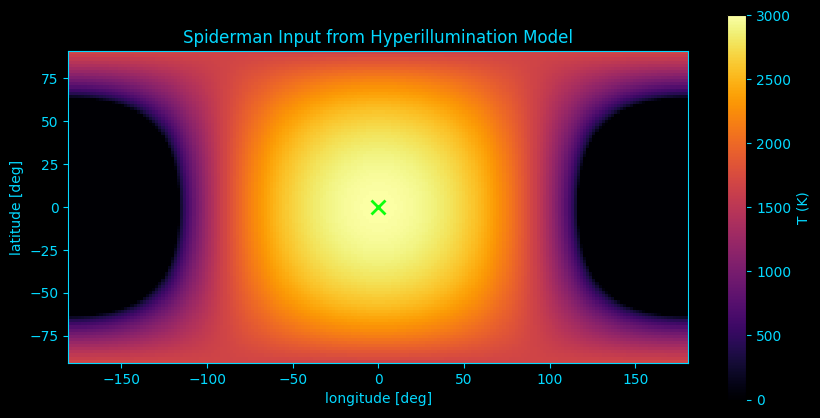

In [7]:
bg, tc = "black", "#04d9ff"   # same dark theme as plot_insolmap(..., theme='black')

fig, ax = plt.subplots(figsize=(10, 5), facecolor=bg)
im = ax.pcolormesh(lo, la, temp_grid, cmap=plt.cm.inferno, shading="auto")   # same colormap as plot_insolmap
ax.plot(0, 0, "x", color="#0cff0c", ms=10, mew=2)   # substellar point, same marker convention as spiderman's plot_square
ax.set_aspect("equal")
ax.set_facecolor(bg)
ax.set_xlabel("longitude [deg]", color=tc)
ax.set_ylabel("latitude [deg]", color=tc)
ax.tick_params(colors=tc)
for spine in ax.spines.values():
    spine.set_color(tc)

cbar = fig.colorbar(im, ax=ax)
cbar.ax.tick_params(colors=tc)
cbar.set_label("T (K)", color=tc)

ax.set_title("Spiderman Input from Hyperillumination Model", color=tc)
plt.show()

### SPIDERMAN phase curve from the custom brightness map (`direct_T`)

In [7]:
t_kopal, thermal_phasecurve_kopal, thermal_fp_kopal, spider_params_kopal = thermal_PhaseCurve(K2_141b, lambda_range, u=u, insolation_model="kopal", filter_path=filter_path, A_B=A_B)
t_naive, thermal_phasecurve_naive, thermal_fp_naive, spider_params_naive = thermal_PhaseCurve(K2_141b, lambda_range, u=u, insolation_model="naive", filter_path=filter_path, A_B=A_B)

#### Brightness Maps

/opt/anaconda3/envs/PhaseCurves/lib/python3.11/site-packages/spiderman/plot.py:133: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 924.855x800 with 5 Axes> which fig.colorbar is called on.
  cbar = plt.colorbar(mycax, cax=cbar_ax)


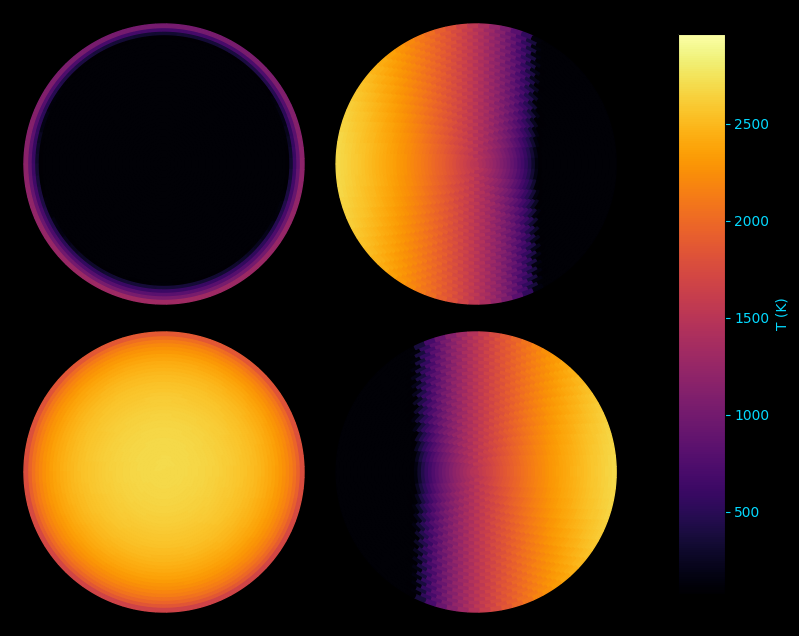

In [9]:
spider_params_kopal.plot_quad(temp_map=True,theme='black')
plt.show()

# phase = 0.25
# spider_params_kopal.plot_planet(phase,use_phase=True,temp_map=True, theme='black')
# plt.show()

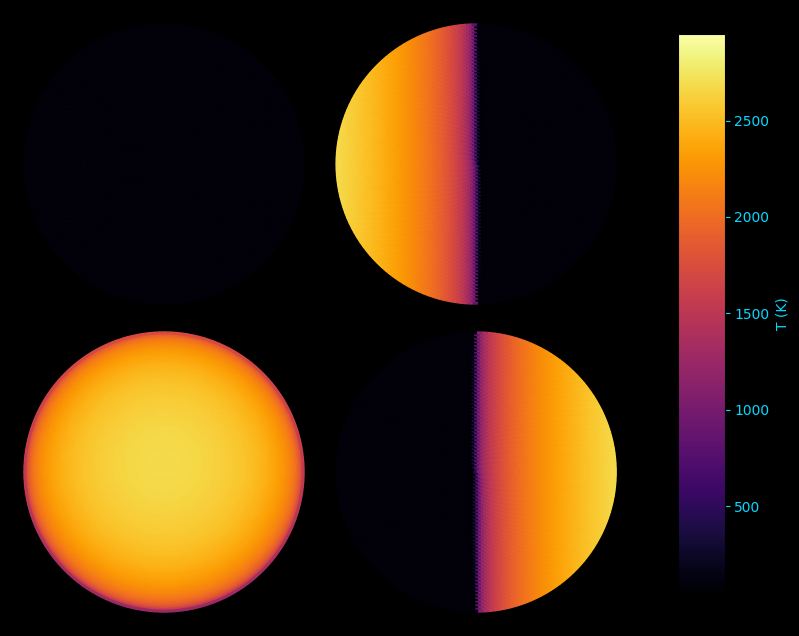

In [10]:
spider_params_naive.plot_quad(temp_map=True,theme='black')
plt.show()

# phase = 0.25
# phase_curve_naive.plot_planet(phase,use_phase=True,temp_map=True, theme='black')
# plt.show()

Slight asymmetry at phase=0 caused by incl = 86.3.

#### Phase Curve

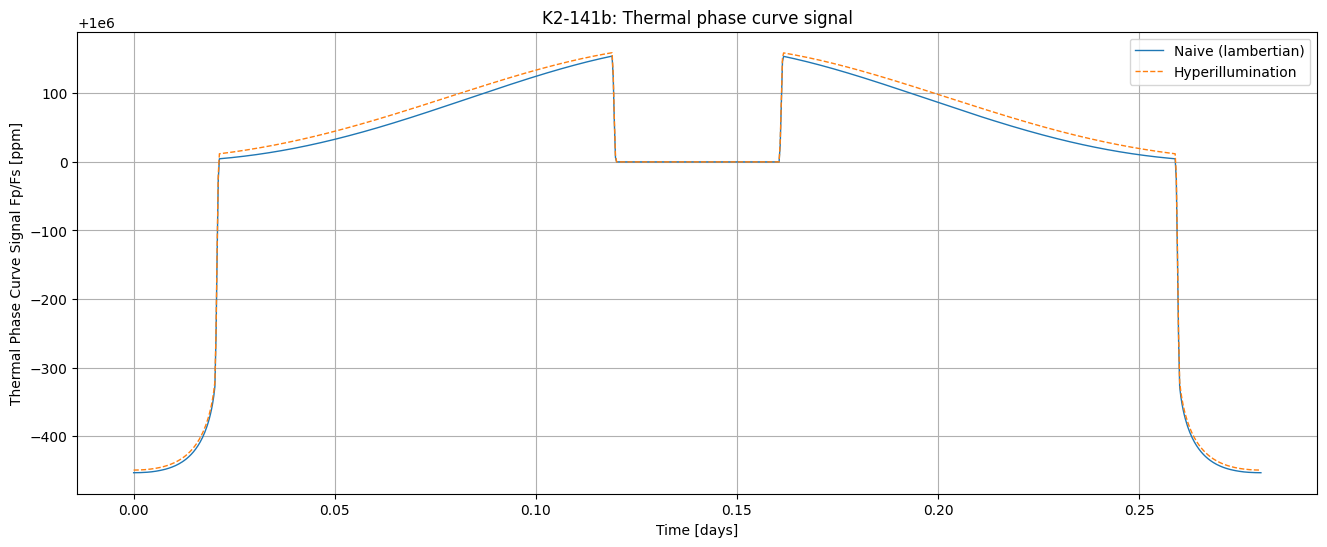

Occultation depth with Hyperillumination: 169.8 ppm   (measured: fp = 142 ppm at 4.5 um)
Occultation depth without Hyperillumination: 168.6 ppm   (measured: fp = 142 ppm at 4.5 um)


In [11]:
plt.figure(figsize=(16, 6))
plt.plot(t_naive, thermal_phasecurve_naive*1e6, linewidth=1, label="Naive (lambertian)")
plt.plot(t_kopal, thermal_phasecurve_kopal*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Phase Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Thermal phase curve signal")
plt.legend()
plt.grid()
plt.show()

print(f"Occultation depth with Hyperillumination: {thermal_fp_kopal:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")
print(f"Occultation depth without Hyperillumination: {thermal_fp_naive:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")

Modelled occultation depth larger than measured by Zieba 2022 (both with and without accounting for hyperillumination). 

Potential reasons:

- Larger Albedo (Zieba 2022 measured Ag=0.28, but this is only in small wavelength band and lambertian reflection assumption likely invalid)
- Slightly different wavelength range / throughput?
- Uncertainty in orbital parameters (especially Rp has a big effect)

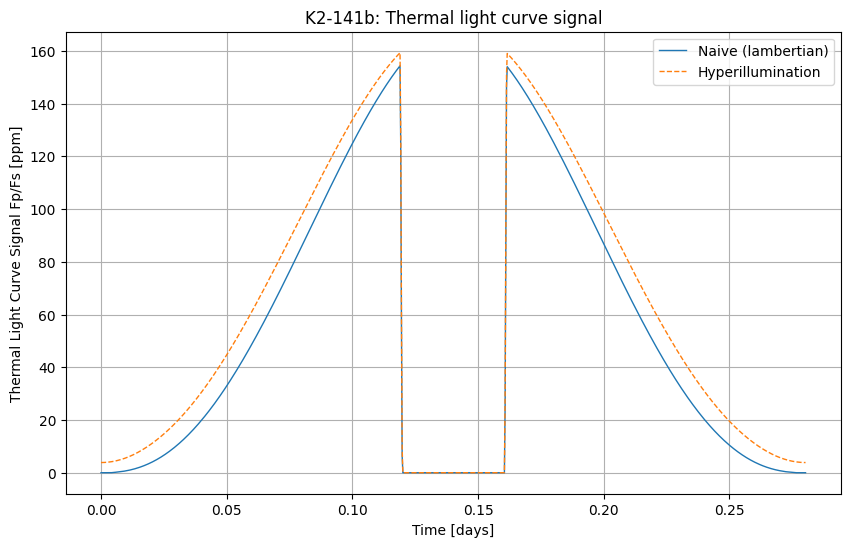

In [12]:
t_kopal, thermal_lightcurve_kopal, _, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, insolation_model="kopal", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=True)
t_naive, thermal_lightcurve_naive, _, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, insolation_model="naive", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=True)

plt.figure(figsize=(10, 6))
plt.plot(t_naive, thermal_lightcurve_naive*1e6, linewidth=1, label="Naive (lambertian)")
plt.plot(t_kopal, thermal_lightcurve_kopal*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Thermal light curve signal")
plt.legend()
plt.grid()
plt.show()

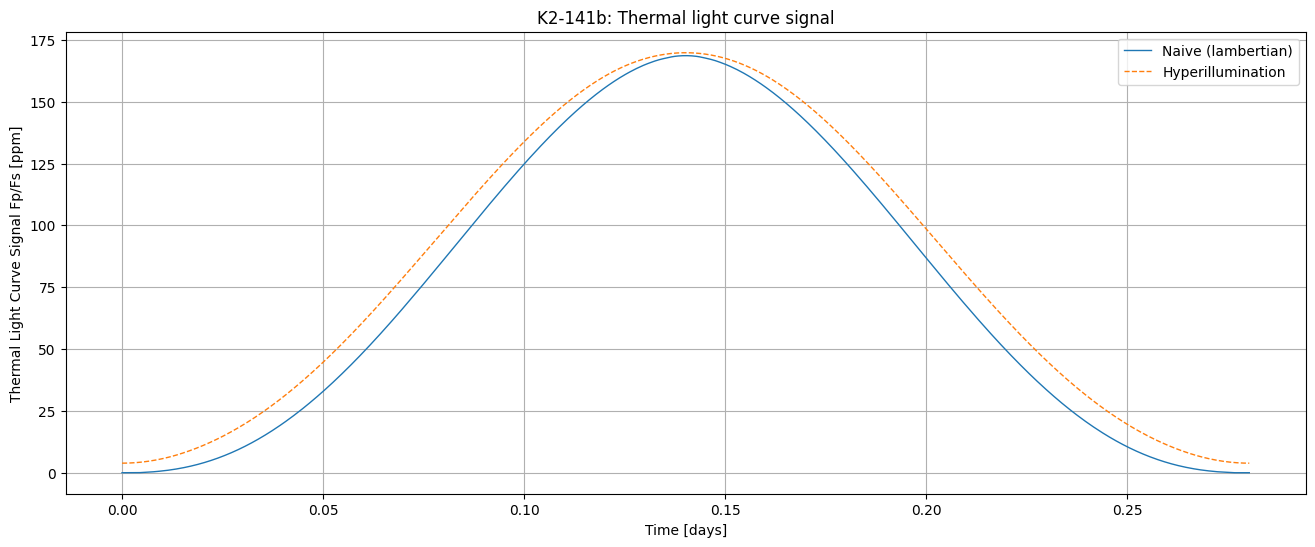

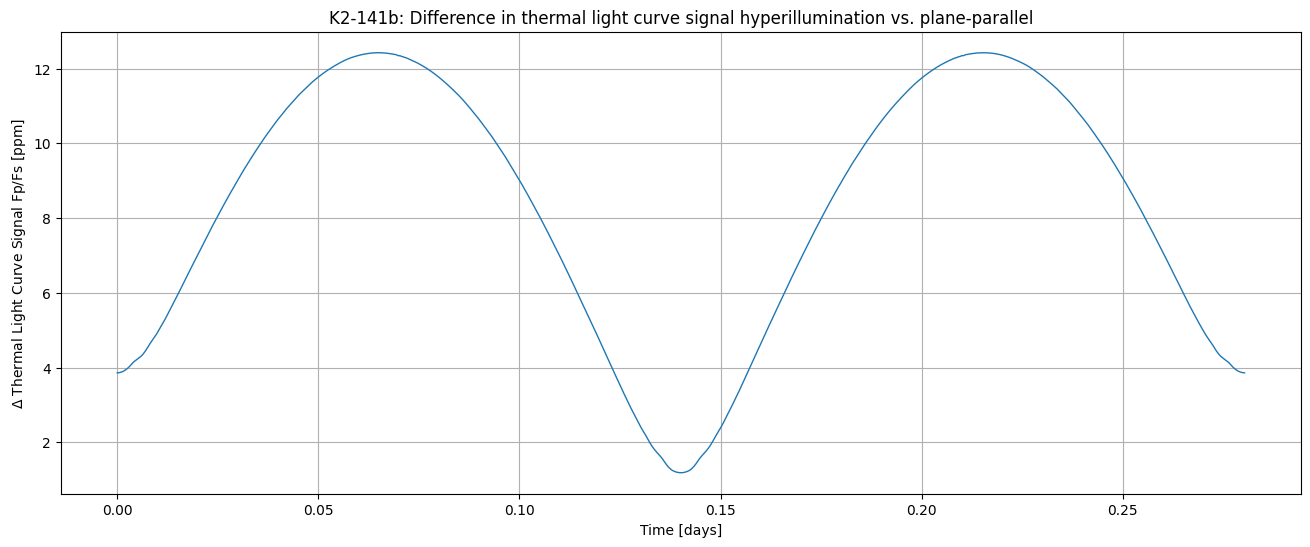

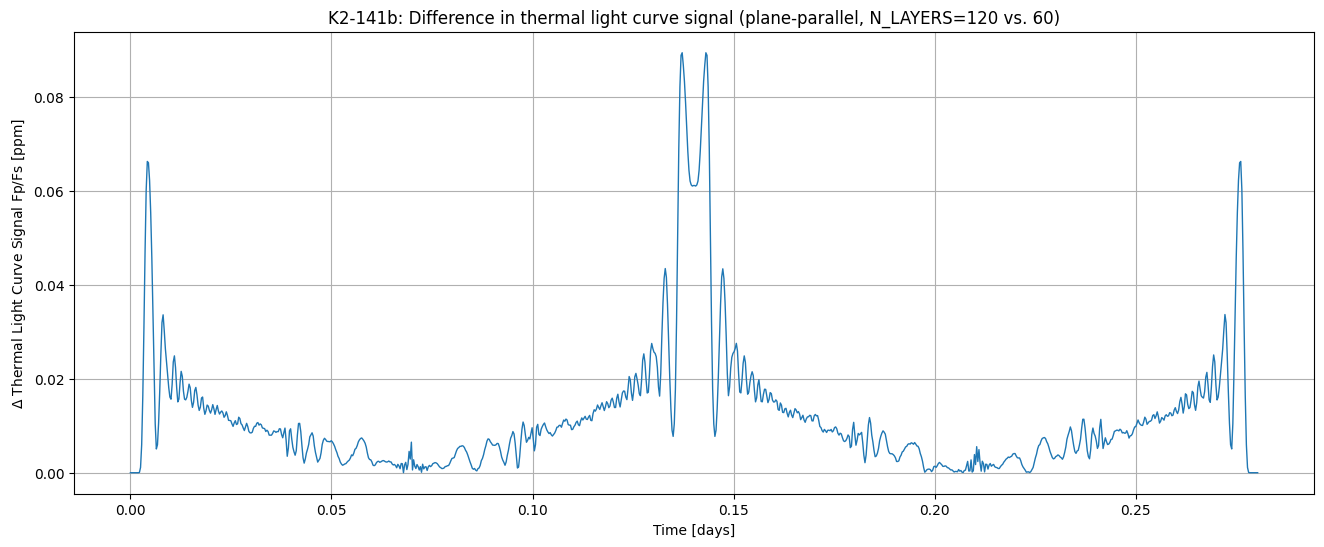

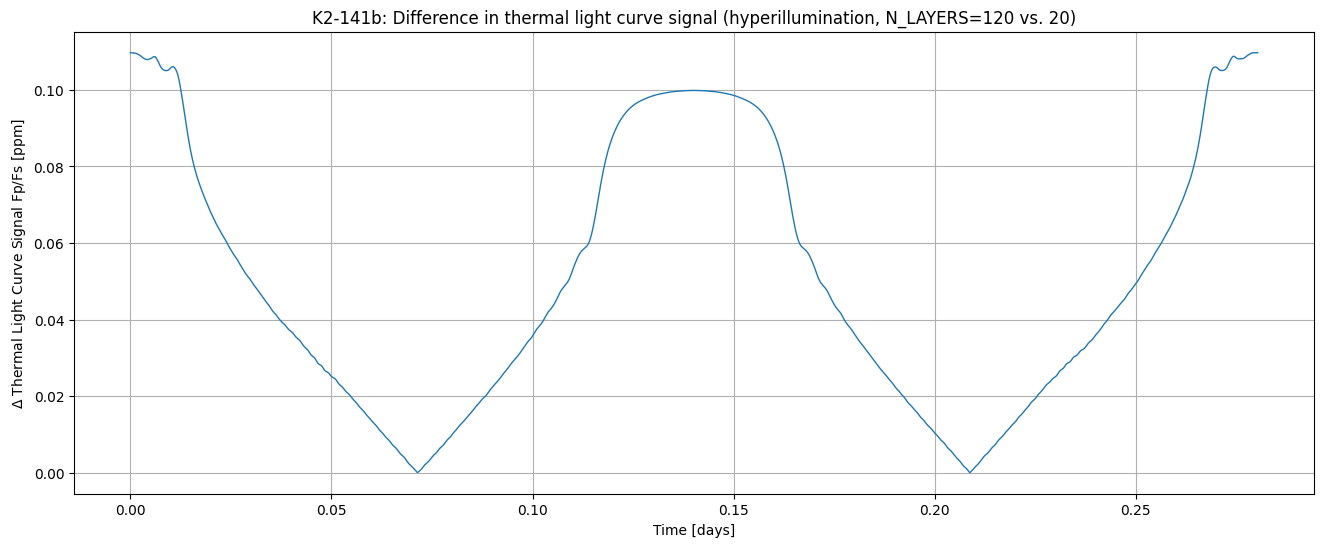

In [13]:
t_kopal, thermal_lightcurve_kopal, _, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, insolation_model="kopal", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=False) # N_LAYERS=40
t_naive, thermal_lightcurve_naive, _, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, insolation_model="naive", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=False) # N_LAYERS=80
t_kopal, thermal_lightcurve_kopal_120, _, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, insolation_model="kopal", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=False, N_LAYERS=120)
t_naive, thermal_lightcurve_naive_120, _, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, insolation_model="naive", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=False, N_LAYERS=120)

plt.figure(figsize=(16, 6))
plt.plot(t_naive, thermal_lightcurve_naive * 1e6, linewidth=1, label="Naive (lambertian)")
plt.plot(t_kopal, thermal_lightcurve_kopal * 1e6, linewidth=1, linestyle="--", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Thermal light curve signal")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()
plt.show()

plt.figure(figsize=(16, 6))
plt.plot(t_naive, (thermal_lightcurve_kopal - thermal_lightcurve_naive) * 1e6, linewidth=1)
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Difference in thermal light curve signal hyperillumination vs. plane-parallel")
#plt.ylim(0., 0.8e-7)
plt.grid()

plt.figure(figsize=(16, 6))
plt.plot(t_naive, np.abs((thermal_lightcurve_naive-thermal_lightcurve_naive_120))*1e6, linewidth=1)
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Difference in thermal light curve signal (plane-parallel, N_LAYERS=120 vs. 60)")
#plt.ylim(0., 0.8e-7)
plt.grid()

plt.figure(figsize=(16, 6))
plt.plot(t_naive, np.abs((thermal_lightcurve_kopal-thermal_lightcurve_kopal_120))*1e6, linewidth=1)
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Difference in thermal light curve signal (hyperillumination, N_LAYERS=120 vs. 20)")
#plt.ylim(0., 0.8e-7)
plt.grid()

- Wiggles are a numerical artefact in naive light curve signal caused by truncation at 90° (Spiderman converges well only for smooth integrands). Can be fixed by setting n_layers = 120.
- Difference in occultation depth between hyperillumination and plane-parallel (naive) model no good proxi for detectability - negligible phase curve differences at alpha=0...

## Consistency Check: Compare custom Spiderman model `insolation=naive` with Spiderman Louden model `F=0`

SPIDERMAN's "Louden" brightness model implements the Kreidberg & Loeb (2016) toy heat-redistribution map with an added internal-heat term:

$$T(\phi,\lambda) = T_\mathrm{int} + \left[\frac{(1-A_B)\,S}{\sigma}\left((1-2F)\cos\phi\cos\lambda + \tfrac{F}{2}\right)\right]^{1/4},$$

on the dayside ($|\lambda| \leq \pi/2$), and $T = T_\mathrm{int} + \left[(1-A_B)\,S\,F/2\sigma\right]^{1/4}$ on the nightside, where $\phi, \lambda$ are latitude/longitude from the substellar point, $S$ the substellar insolation, and $F \in [0, 0.5]$ the redistribution parameter ($F=0$: instant reradiation, 0 K nightside; $F=0.5$: isothermal planet). It describes a bare, grey, zero-heat-capacity surface in local radiative equilibrium, and is symmetric about the substellar point by construction (no advection, hence no hotspot offset). With $F=0$ and $T_\mathrm{int}=0$ it is analytically identical to the naive plane-parallel map built here from `naive_insolation` + `BBtemp_from_insolation`, and therefore serves as an independent check on the `direct_T` pipeline.

In [14]:
t_naive, thermal_lightcurve_naive, _, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, insolation_model="naive", filter_path=filter_path, A_B=A_B, include_transit=False)

In [15]:
t_louden, lightcurve_louden, fp_louden, _ = Louden_PhaseCurve(K2_141b, lambda_range, u=u, filter_path=filter_path, A_B=A_B, include_transit=False)

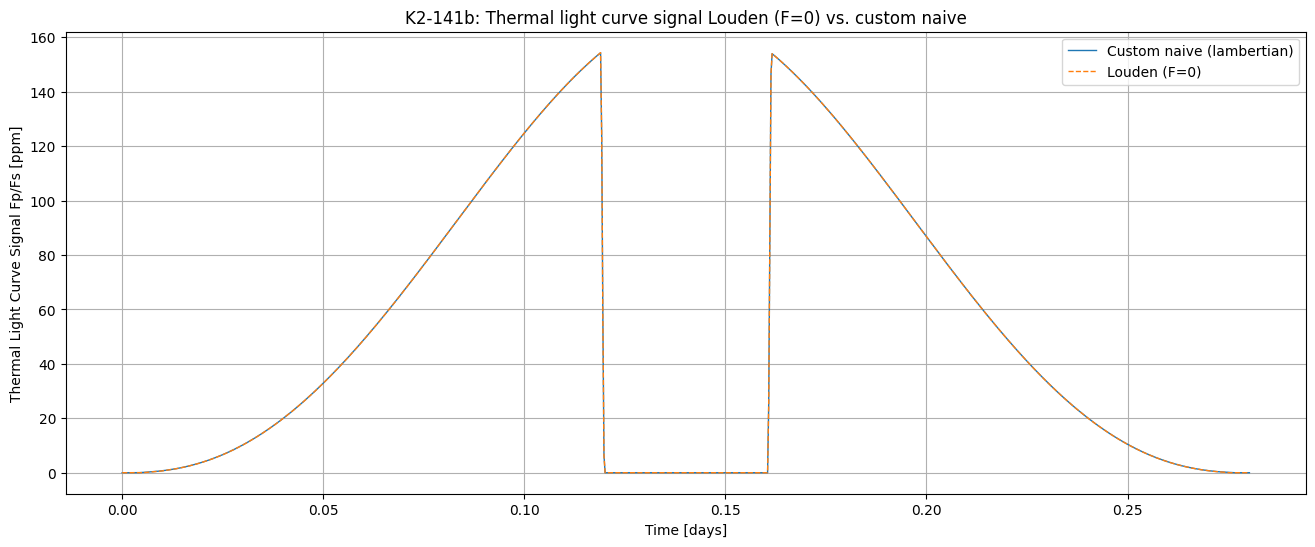

Occultation depth Louden (F=0): 168.7 ppm   (measured: fp = 142 ppm at 4.5 um)
Occultation depth custom naive: 168.6 ppm   (measured: fp = 142 ppm at 4.5 um)


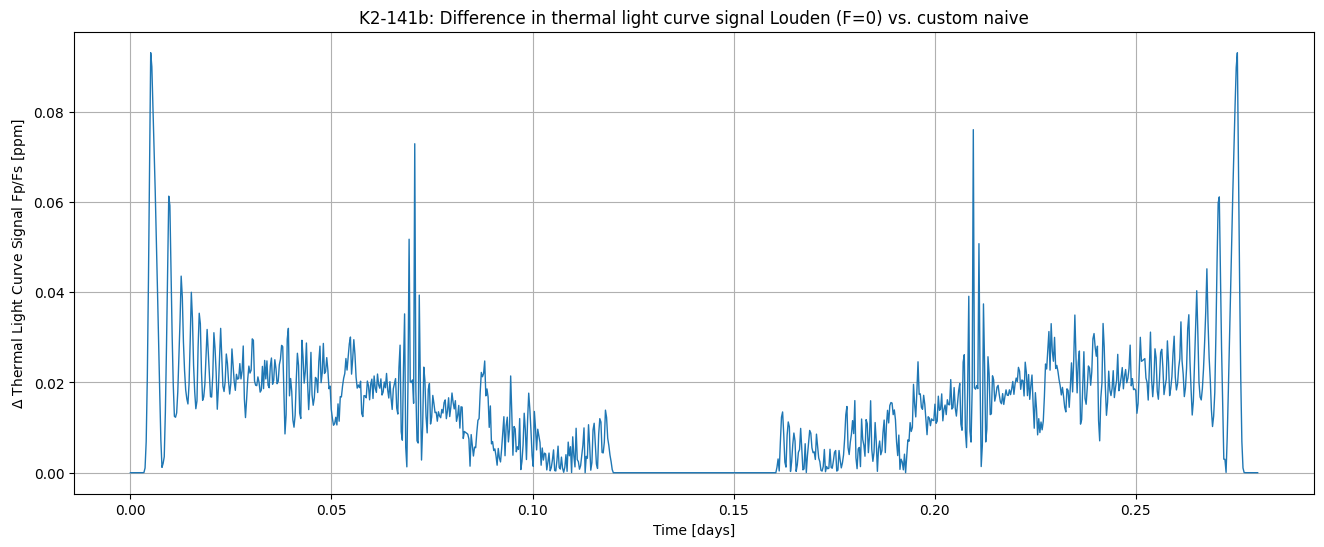

In [16]:
plt.figure(figsize=(16, 6))
plt.plot(t_naive, thermal_lightcurve_naive*1e6, linewidth=1, label="Custom naive (lambertian)")
plt.plot(t_naive, lightcurve_louden*1e6, linewidth=1, linestyle="--", label="Louden (F=0)")
plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Thermal light curve signal Louden (F=0) vs. custom naive")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()
plt.show()

plt.figure(figsize=(16, 6))
plt.plot(t_naive, np.abs((lightcurve_louden-thermal_lightcurve_naive))*1e6, linewidth=1)
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Difference in thermal light curve signal Louden (F=0) vs. custom naive")
#plt.ylim(0., 0.8e-7)
plt.grid()

print(f"Occultation depth Louden (F=0): {fp_louden:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")
print(f"Occultation depth custom naive: {thermal_fp_naive:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")

## Parameter Sweep

#### Sweep 1: Bond albedo $A_B$

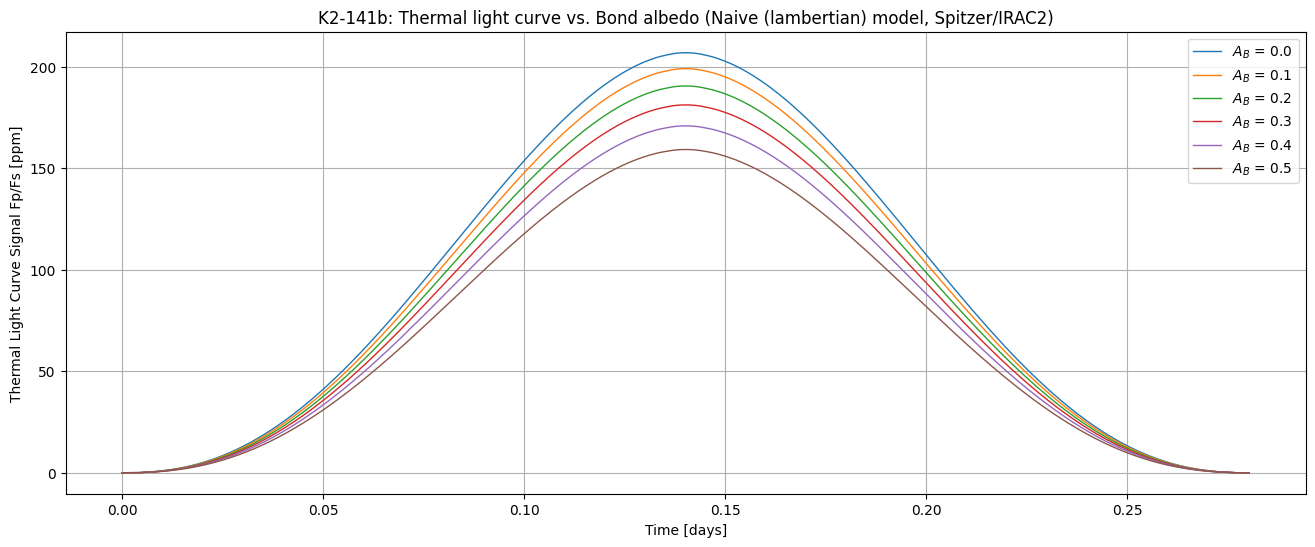

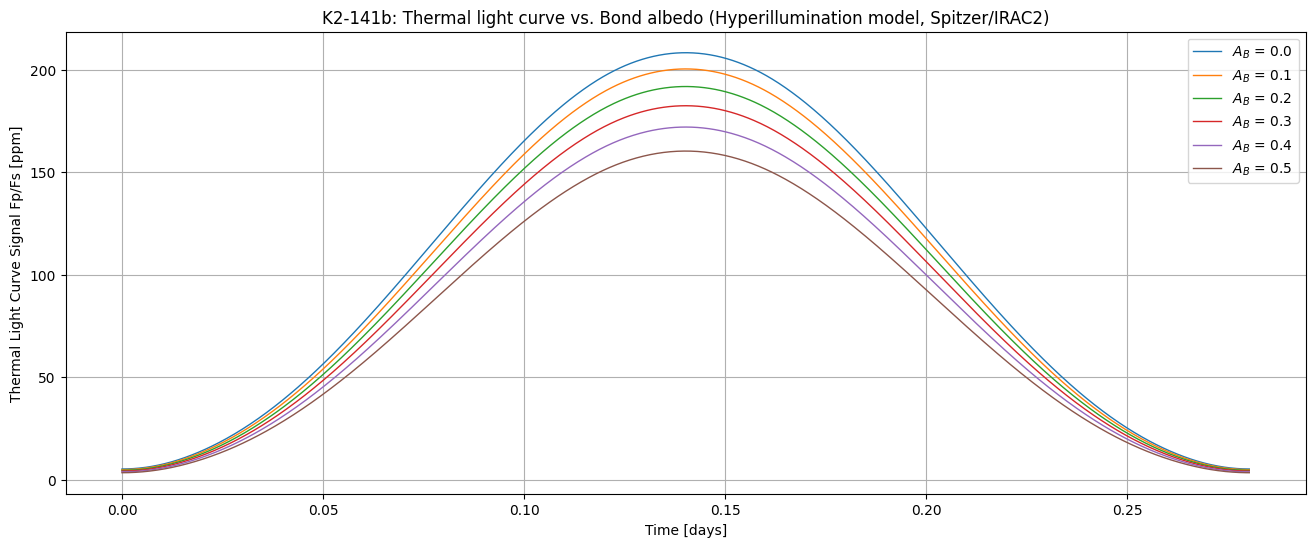

In [17]:
A_B_sweep = np.arange(0.0, 0.51, 0.1)  # 0.0, 0.1, ..., 0.5

for insolation_model, label in [("naive", "Naive (lambertian)"), ("kopal", "Hyperillumination")]:
    plt.figure(figsize=(16, 6))
    for A_B_val in A_B_sweep:
        t_sw, lc_sw, _, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, insolation_model=insolation_model, filter_path=filter_path, A_B=A_B_val, include_transit=False, include_occultation=False)
        plt.plot(t_sw, lc_sw*1e6, linewidth=1, label=f"$A_B$ = {A_B_val:.1f}")
    plt.xlabel("Time [days]")
    plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
    plt.title(f"K2-141b: Thermal light curve vs. Bond albedo ({label} model, Spitzer/IRAC2)")
    plt.legend()
    plt.grid()
    plt.show()

#### Sweep 2: Wavelength range

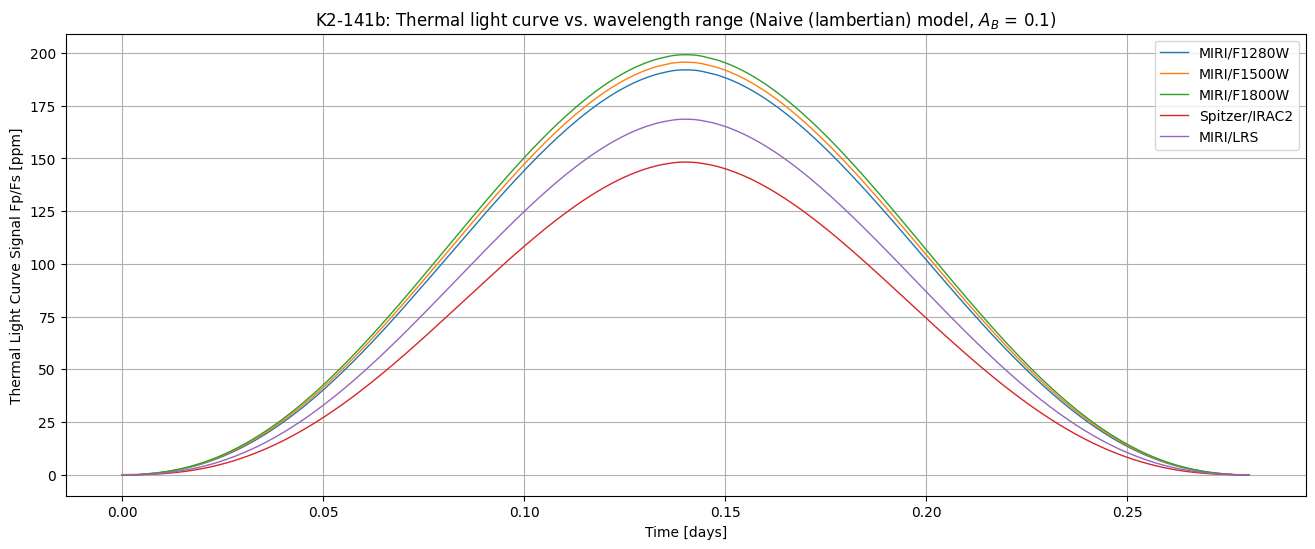

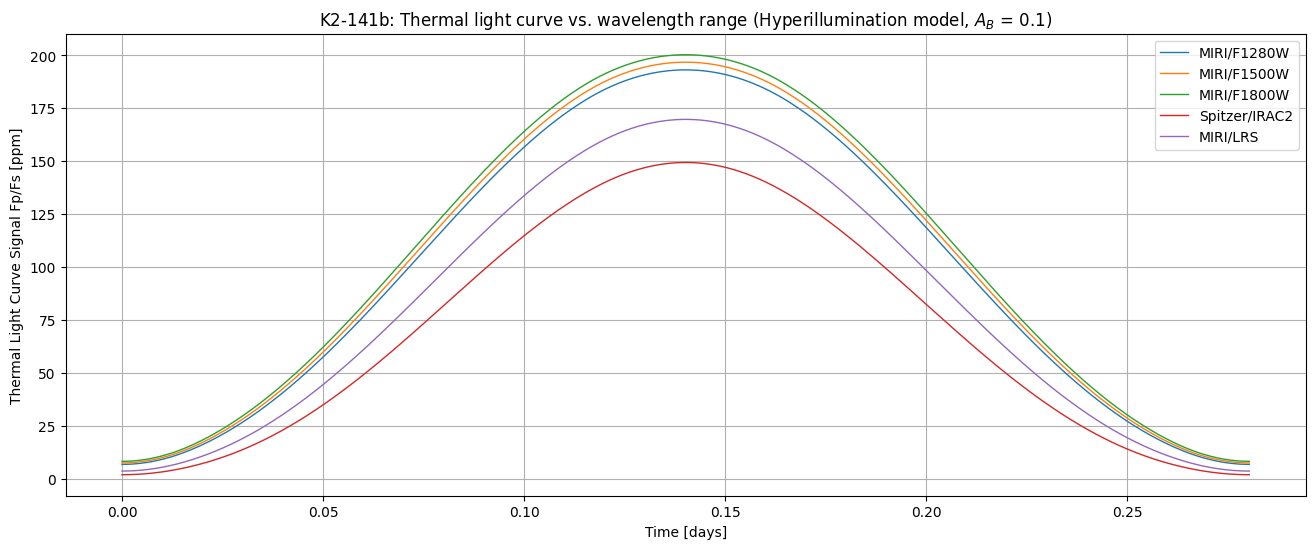

In [18]:
for insolation_model, label in [("naive", "Naive (lambertian)"), ("kopal", "Hyperillumination")]:
    plt.figure(figsize=(16, 6))
    for band_name, band_range in filter_lambda_ranges.items():
        lambda_range_sw = band_range
        filter_path_sw = filter_paths[band_name]
        t_sw, lc_sw, _, _ = thermal_PhaseCurve(K2_141b, lambda_range_sw, u=u, insolation_model=insolation_model, filter_path=filter_path_sw, A_B=A_B, include_transit=False, include_occultation=False)
        plt.plot(t_sw, lc_sw*1e6, linewidth=1, label=band_name)
    plt.xlabel("Time [days]")
    plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
    plt.title(f"K2-141b: Thermal light curve vs. wavelength range ({label} model, $A_B$ = 0.1)")
    plt.legend()
    plt.grid()
    plt.show()

## Difference between hyperillumination and naive model 

Ceteris paribus sweeps: for each parameter, all other parameters are held at the K2-141b baseline values set at the top of this notebook (`period, incl, ecc, w, rp, a, T_eff, u, A_B, lambda_range, filter_path`), and only the swept parameter is varied. Each plot shows the Hyperillumination - Naive difference in the thermal light curve signal.

In [19]:
from dataclasses import replace

PLANET_FIELDS = {"period", "incl", "ecc", "w", "r1", "r2", "R", "T2_eff", "a_AU"}

# baseline non-swept thermal_PhaseCurve kwargs (the planet is held at K2_141b)
baseline_kwargs = dict(lambda_range=lambda_range, filter_path=filter_path, u=u, A_B=A_B)

def sweep_hyperillumination_minus_naive(param_name, values, label_fmt, title_suffix, planet=K2_141b, **base_kwargs):
    plt.figure(figsize=(16, 6))
    for val in values:
        p = replace(planet, **{param_name: val}) if param_name in PLANET_FIELDS else planet
        kwargs = dict(base_kwargs)
        if param_name not in PLANET_FIELDS: kwargs[param_name] = val
        t_k, lc_k, _, _ = thermal_PhaseCurve(p, insolation_model="kopal", include_transit=False, include_occultation=False, **kwargs)
        _,   lc_n, _, _ = thermal_PhaseCurve(p, insolation_model="naive", include_transit=False, include_occultation=False, **kwargs)
        if param_name=="period": plt.plot(t_k/val, (lc_k - lc_n)*1e6, linewidth=1, label=label_fmt(val))
        else: plt.plot(t_k, (lc_k - lc_n)*1e6, linewidth=1, label=label_fmt(val))
    if param_name=="period": plt.xlabel("Orbital Phase")
    else: plt.xlabel("Time [days]")
    plt.ylabel(r"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm] (Hyperillumination $-$ Naive)")
    plt.title(f"K2-141b: Hyperillumination $-$ Naive vs. {title_suffix}")
    plt.legend()
    plt.grid()
    plt.show()

#### Bond albedo $A_B$

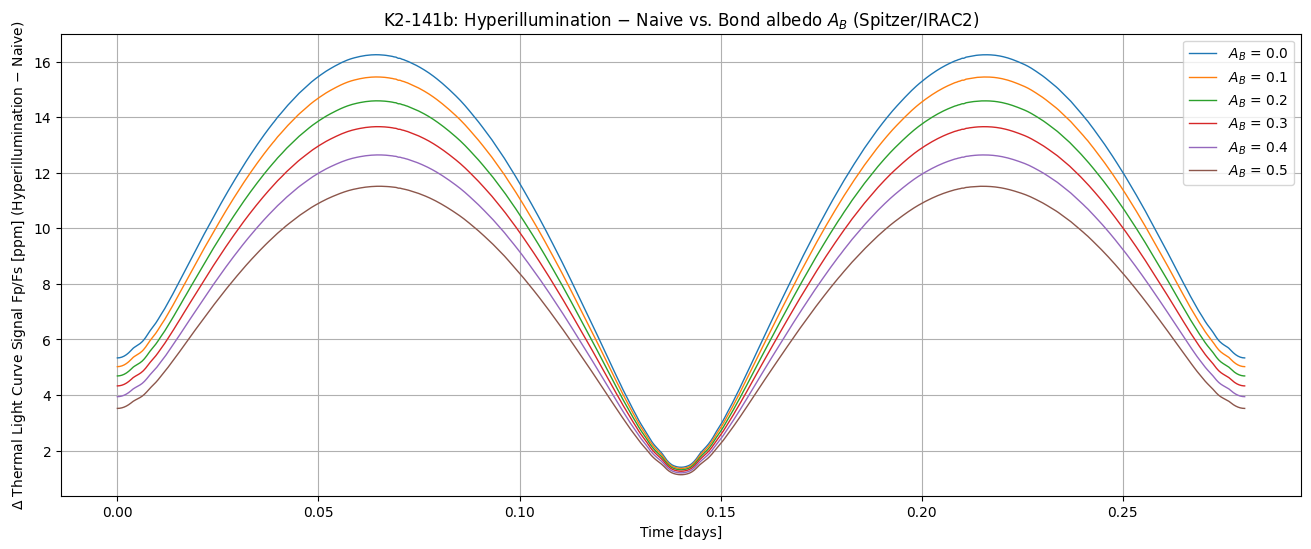

In [20]:
sweep_hyperillumination_minus_naive("A_B", np.arange(0.0, 0.51, 0.1), lambda v: f"$A_B$ = {v:.1f}", "Bond albedo $A_B$ (Spitzer/IRAC2)", **baseline_kwargs)

#### Wavelength range

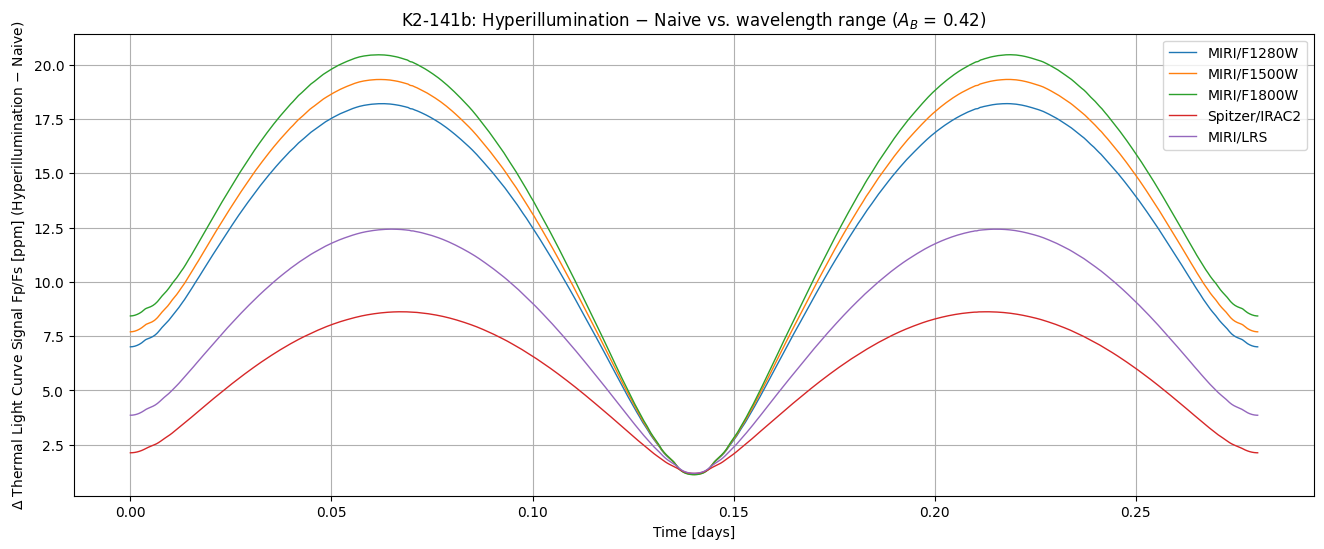

In [21]:
# lambda_range/filter_path values differ per band -> special-cased instead of using the generic helper
plt.figure(figsize=(16, 6))
for band_name, band_range in filter_lambda_ranges.items():
    kwargs = dict(baseline_kwargs)
    kwargs["lambda_range"] = band_range
    kwargs["filter_path"] = filter_paths[band_name]
    t_k, lc_k, _, _ = thermal_PhaseCurve(K2_141b, include_transit=False, include_occultation=False, insolation_model="kopal", **kwargs)
    _,   lc_n, _, _ = thermal_PhaseCurve(K2_141b, include_transit=False, include_occultation=False, insolation_model="naive", **kwargs)
    plt.plot(t_k, (lc_k - lc_n)*1e6, linewidth=1, label=band_name)
plt.xlabel("Time [days]")
plt.ylabel(r"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm] (Hyperillumination $-$ Naive)")
plt.title(f"K2-141b: Hyperillumination $-$ Naive vs. wavelength range ($A_B$ = {A_B:.2f})")
plt.legend()
plt.grid()
plt.show()

#### Stellar limb darkening $u$

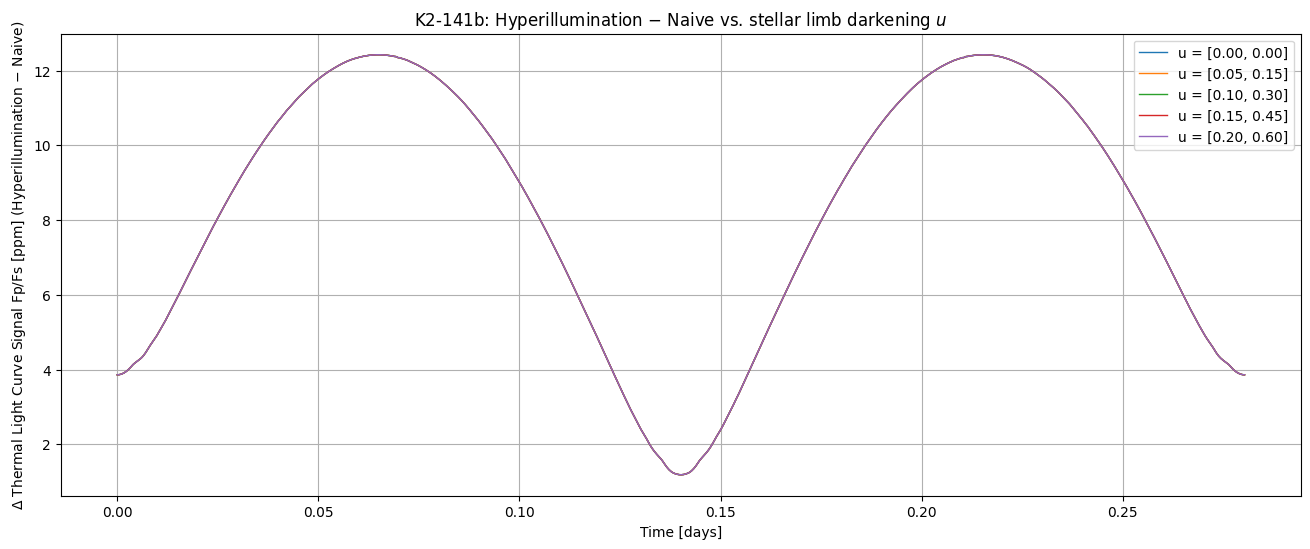

In [22]:
# TODO only limb darkening effect is in hyperillumination insolation model - to be modified to quadratic
u_factors = np.array([0.0, 0.5, 1.0, 1.5, 2.0])  # scaling the K2-141b placeholder u = [0.1, 0.3]
sweep_hyperillumination_minus_naive("u", [list(f*np.array(u)) for f in u_factors], lambda v: f"u = [{v[0]:.2f}, {v[1]:.2f}]", "stellar limb darkening $u$", **baseline_kwargs)

#### Stellar effective temperature $T_\mathrm{eff}$

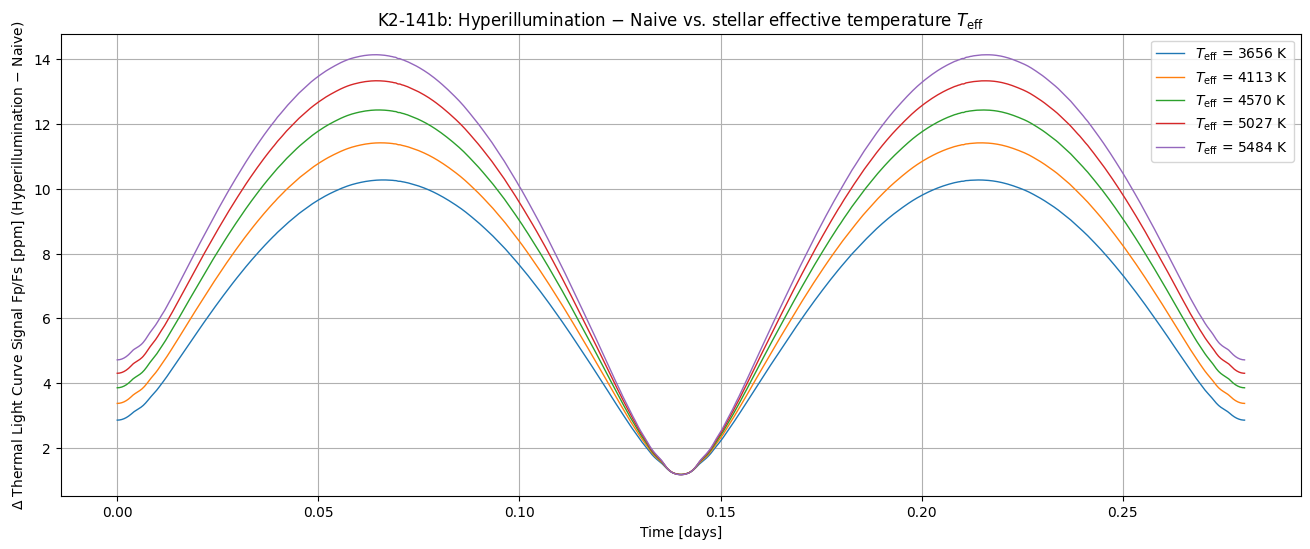

In [23]:
factors = np.array([0.8, 0.9, 1.0, 1.1, 1.2])  # +/- 20% around each K2-141b baseline value

sweep_hyperillumination_minus_naive("T2_eff", T_eff*factors, lambda v: f"$T_\\mathrm{{eff}}$ = {v:.0f} K", "stellar effective temperature $T_\\mathrm{eff}$", **baseline_kwargs)

#### Planet radius / Stellar radius $r_p$

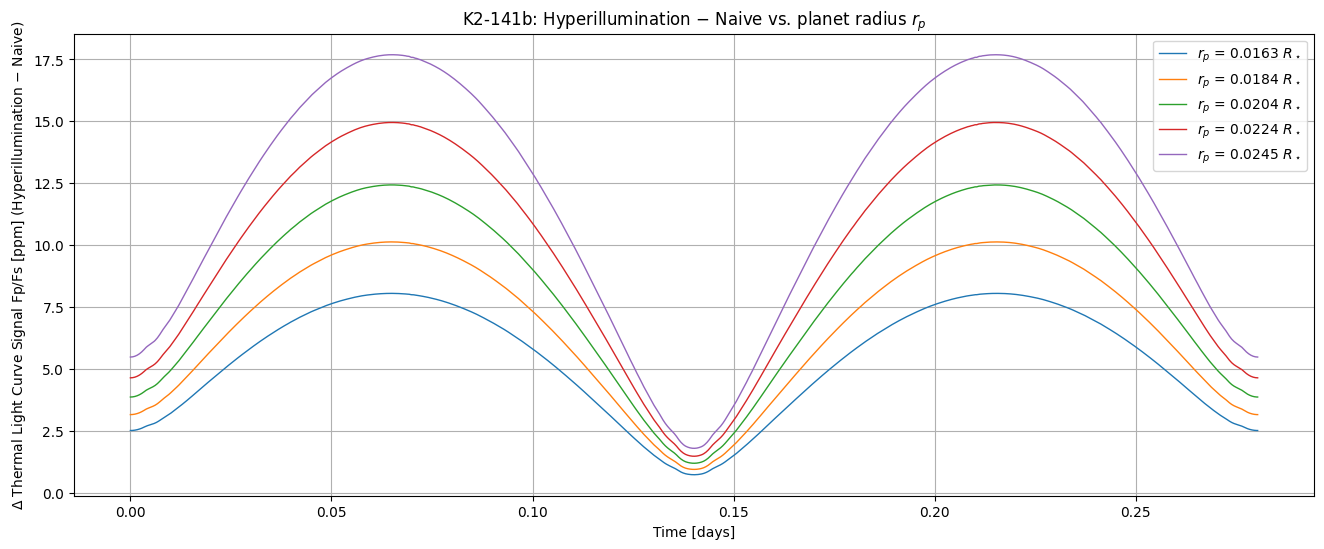

In [24]:
sweep_hyperillumination_minus_naive("r1", rp*factors, lambda v: f"$r_p$ = {v:.4f} $R_\\star$", "planet radius $r_p$", **baseline_kwargs)

#### Semi-major axis / Stellar radius $a$

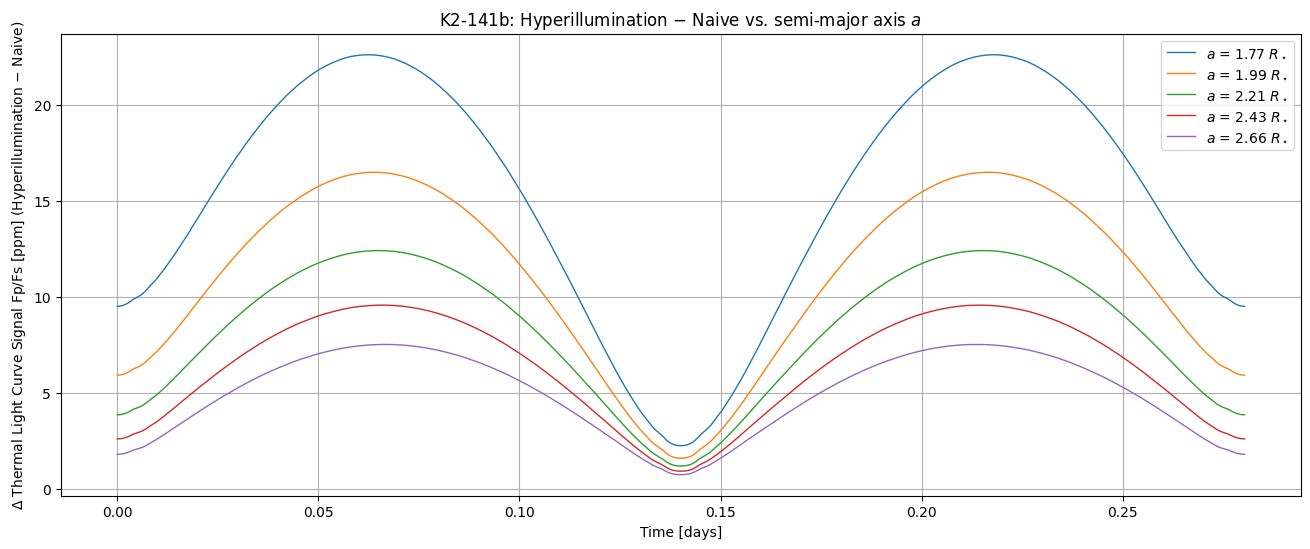

In [25]:
sweep_hyperillumination_minus_naive( "R", a*factors, lambda v: f"$a$ = {v:.2f} $R_\\star$", "semi-major axis $a$", **baseline_kwargs)

#### Orbital period

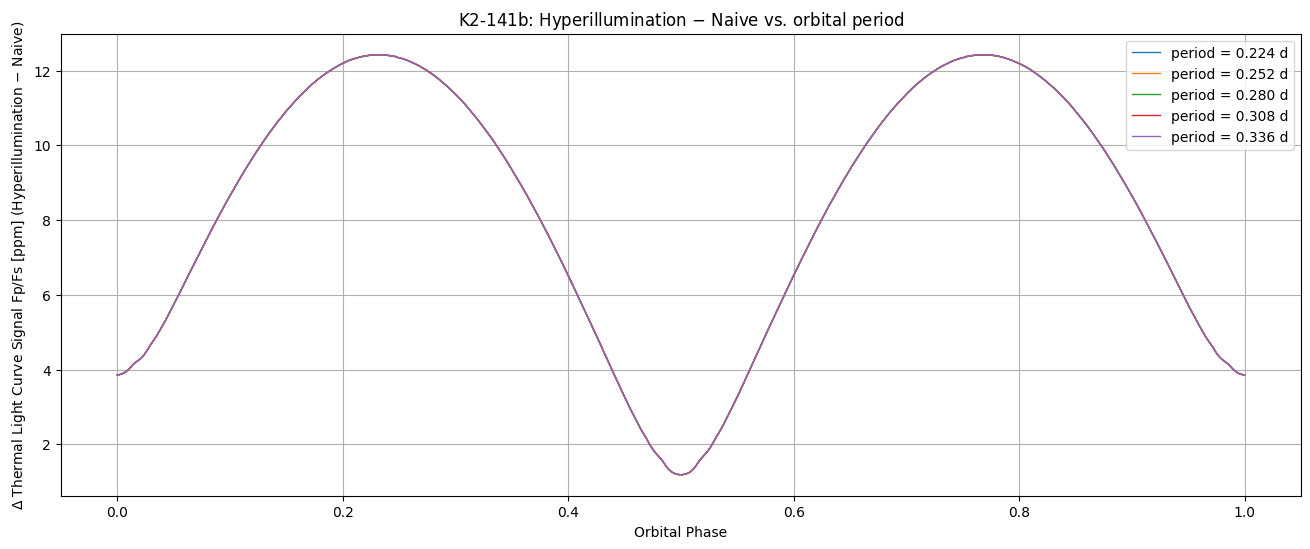

In [26]:
sweep_hyperillumination_minus_naive("period", period*factors, lambda v: f"period = {v:.3f} d", "orbital period", **baseline_kwargs)